# ML Assignment 2 
**Dataset:** Predict Students' Dropout and Academic Success (UCI ML Repository, ID 697)

**Task:** Multi-class classification — predict whether a student will be a **Dropout**, stay **Enrolled**, or **Graduate**.

| Property | Value |
|---|---|
| Instances | 4,424 |
| Features | 36 (demographic, socio-economic, academic path, 1st/2nd semester performance, macro-economic) |
| Target classes | Dropout / Enrolled / Graduate (3 classes) |
| Missing values | None |

**Models implemented (same dataset, same train/test split):**
1. Logistic Regression
2. Decision Tree Classifier
3. K-Nearest Neighbour Classifier
4. Naive Bayes (Gaussian)
5. Support Vector Machine

**Metrics for each model:** Accuracy, AUC, Precision, Recall, F1, MCC.


## 1. Imports & configuration

In [ ]:
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, confusion_matrix,
                             classification_report, roc_curve, auc)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
TEST_SIZE    = 0.20
DATA_PATH    = "data.csv"   
MODEL_DIR    = "model"
TEST_CSV     = "test_data.csv"
TARGET       = "Target"

os.makedirs(MODEL_DIR, exist_ok=True)
np.random.seed(RANDOM_STATE)

## 2. Load the dataset
The UCI file is **semicolon-separated**, and one column header (`Daytime/evening attendance`) contains a trailing tab character.

In [ ]:
def load_dataset(path):
    df = pd.read_csv(path, sep=";")
    if df.shape[1] == 1:                      
        df = pd.read_csv(path, sep=",")
    df.columns = df.columns.str.strip()        
    return df

df = load_dataset(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## 3. Exploratory Data Analysis

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

In [4]:
print("Missing values in total:", int(df.isnull().sum().sum()))
print("Duplicate rows         :", int(df.duplicated().sum()))
print("Number of features     :", df.shape[1] - 1)
print("Number of instances    :", df.shape[0])

Missing values in total: 0
Duplicate rows         : 0
Number of features     : 36
Number of instances    : 4424


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Marital status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
Application mode,4424.0,18.669078,17.484682,1.00,1.00,17.000000,39.000000,57.000000
Application order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
Course,4424.0,8856.642631,2063.566416,33.00,9085.00,9238.000000,9556.000000,9991.000000
Daytime/evening attendance,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
Previous qualification,4424.0,4.577758,10.216592,1.00,1.00,1.000000,1.000000,43.000000
Previous qualification (grade),4424.0,132.613314,13.188332,95.00,125.00,133.100000,140.000000,190.000000
Nacionality,4424.0,1.873192,6.914514,1.00,1.00,1.000000,1.000000,109.000000
Mother's qualification,4424.0,19.561935,15.603186,1.00,2.00,19.000000,37.000000,44.000000
Father's qualification,4424.0,22.275316,15.343108,1.00,3.00,19.000000,37.000000,44.000000


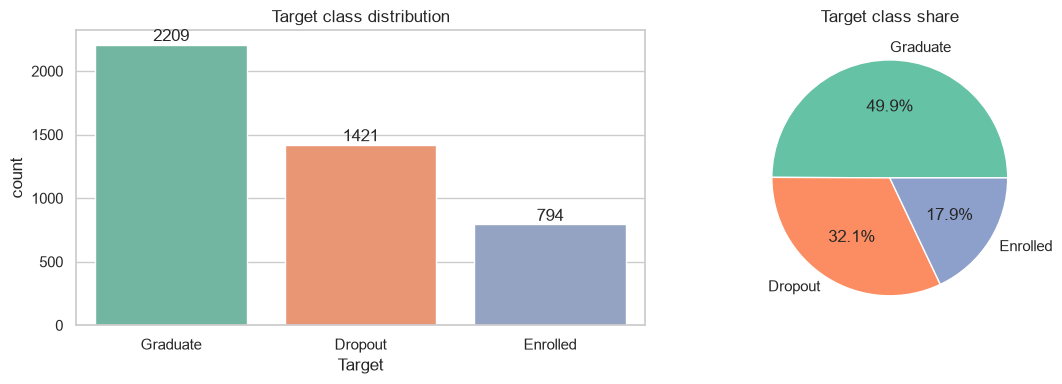

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
counts = df[TARGET].value_counts()
sns.countplot(x=TARGET, data=df, order=counts.index, ax=ax[0], palette="Set2")
ax[0].set_title("Target class distribution")
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                   ha="center", va="bottom")
ax[1].pie(counts, labels=counts.index, autopct="%1.1f%%", colors=sns.color_palette("Set2"))
ax[1].set_title("Target class share")
plt.tight_layout(); plt.show()
print(counts)

The classes are **imbalanced** (Graduate ≈ 50%, Dropout ≈ 32%, Enrolled ≈ 18%).
Because of this we (a) use a **stratified** train/test split and (b) report **weighted** precision/recall/F1 alongside MCC, which is robust to imbalance.

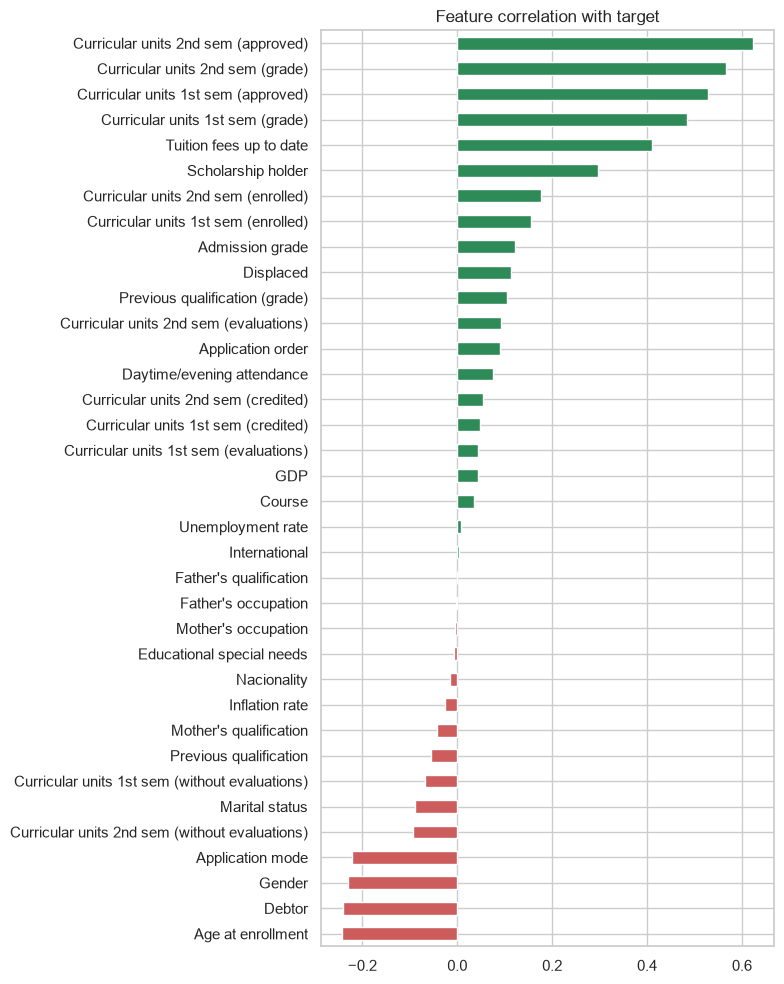

In [7]:
# Correlation of each feature with the encoded target (Dropout=0, Enrolled=1, Graduate=2)
tmp = df.copy()
tmp["_target_code"] = LabelEncoder().fit_transform(tmp[TARGET])
corr = tmp.drop(columns=[TARGET]).corr()["_target_code"].drop("_target_code").sort_values()

plt.figure(figsize=(8, 10))
corr.plot(kind="barh", color=np.where(corr > 0, "seagreen", "indianred"))
plt.title("Feature correlation with target")
plt.tight_layout(); plt.show()

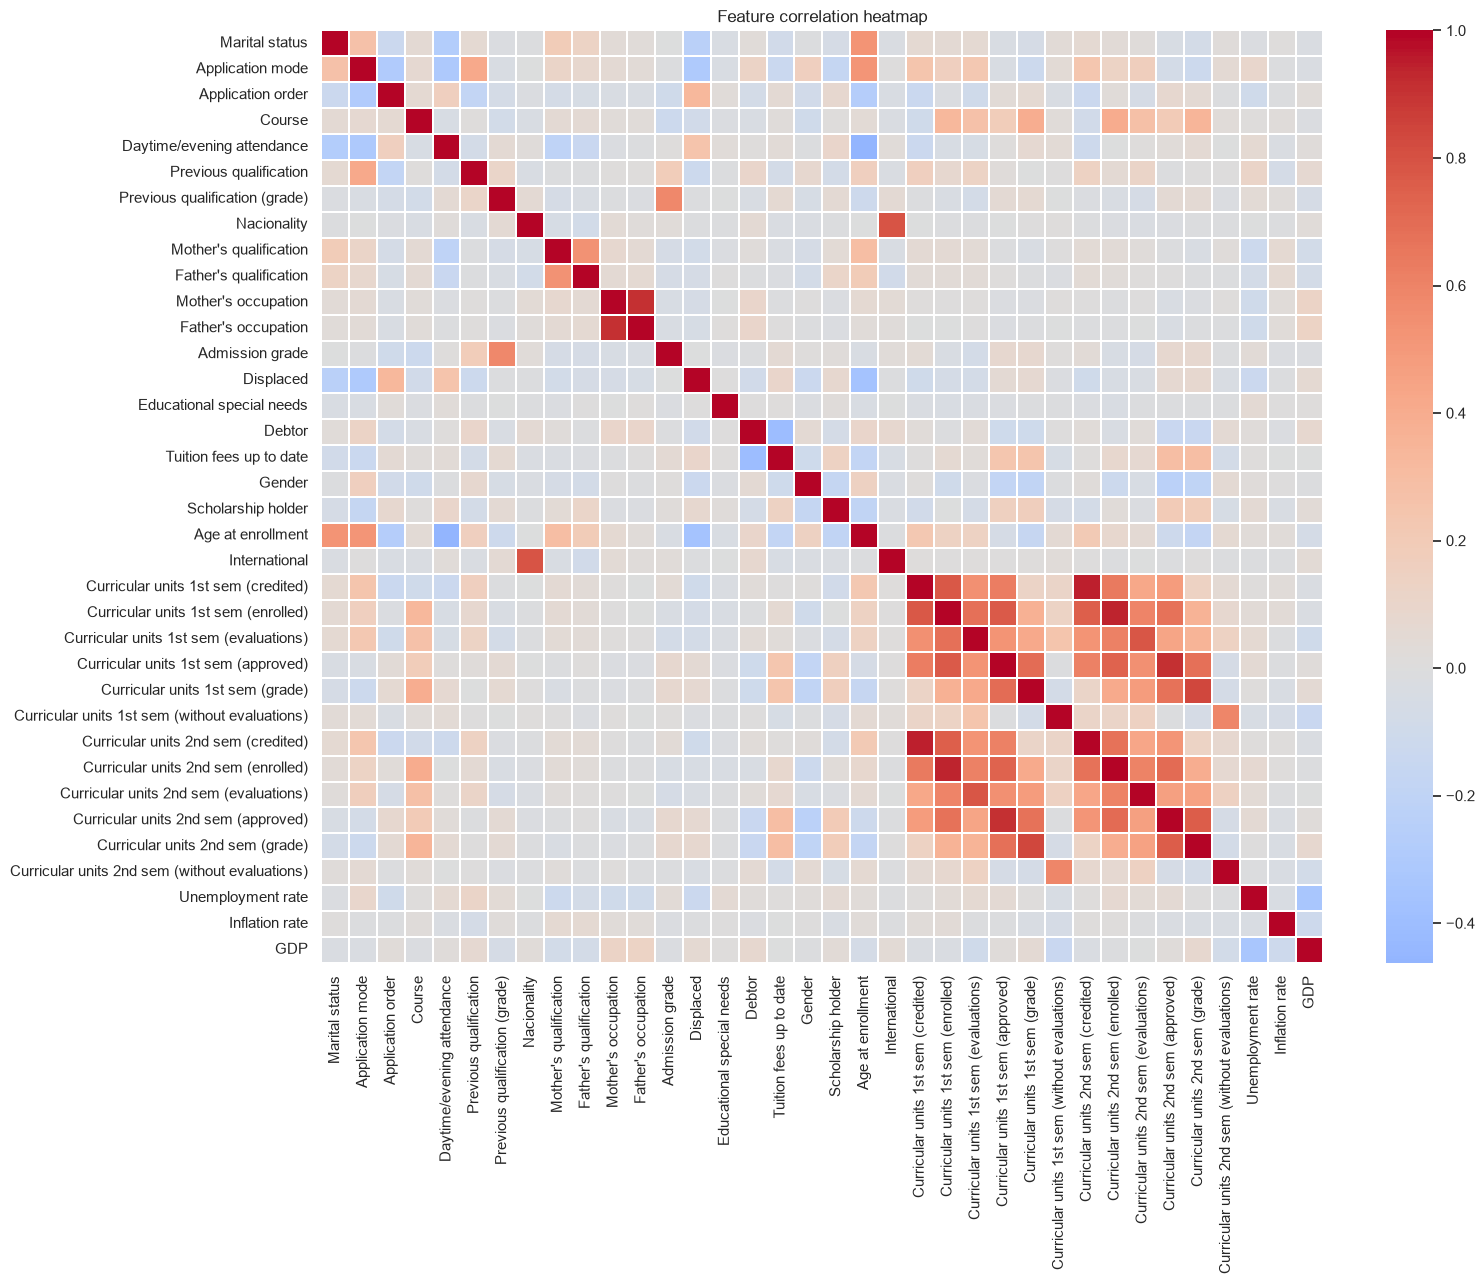

In [8]:
plt.figure(figsize=(16, 13))
sns.heatmap(df.drop(columns=[TARGET]).corr(), cmap="coolwarm", center=0, linewidths=0.3)
plt.title("Feature correlation heatmap")
plt.tight_layout(); plt.show()

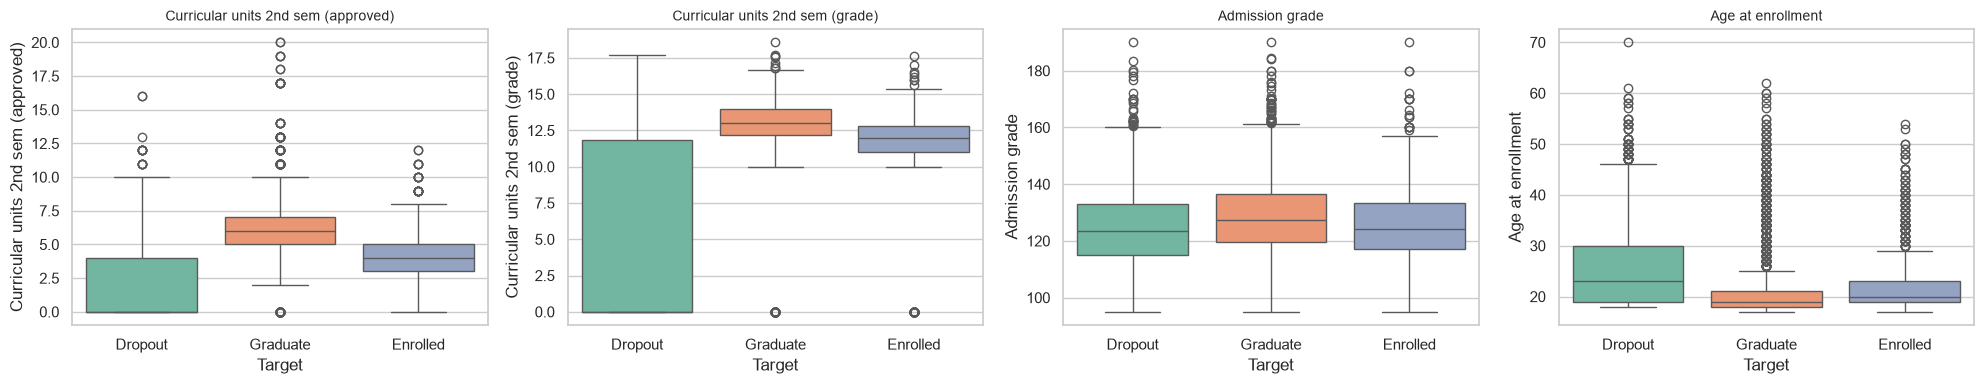

In [9]:
key_feats = [c for c in ["Curricular units 2nd sem (approved)", "Curricular units 2nd sem (grade)",
                         "Admission grade", "Age at enrollment"] if c in df.columns]
fig, axes = plt.subplots(1, len(key_feats), figsize=(5 * len(key_feats), 4))
for a, c in zip(np.atleast_1d(axes), key_feats):
    sns.boxplot(x=TARGET, y=c, data=df, ax=a, palette="Set2")
    a.set_title(c, fontsize=10)
plt.tight_layout(); plt.show()

## 4. Preprocessing
- All 36 features are already numeric (categorical attributes are integer-coded by the dataset authors), so no one-hot encoding is required.
- Target labels are encoded with `LabelEncoder` (saved for the app to decode predictions).
- `StandardScaler` is placed **inside each model pipeline**, so it is fit only on training data.

In [10]:
X = df.drop(columns=[TARGET])
y_raw = df[TARGET]

le = LabelEncoder()
y = le.fit_transform(y_raw)
CLASS_NAMES = list(le.classes_)
print("Class mapping:", dict(zip(CLASS_NAMES, range(len(CLASS_NAMES)))))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train class share:", np.round(np.bincount(y_train) / len(y_train), 3))
print("Test  class share:", np.round(np.bincount(y_test) / len(y_test), 3))

Class mapping: {'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}
Train: (3539, 36)  Test: (885, 36)
Train class share: [0.321 0.179 0.499]
Test  class share: [0.321 0.18  0.499]


In [ ]:
test_df = X_test.copy()
test_df[TARGET] = le.inverse_transform(y_test)
test_df.to_csv(TEST_CSV, index=False)

joblib.dump(le, os.path.join(MODEL_DIR, "label_encoder.joblib"))
with open(os.path.join(MODEL_DIR, "feature_columns.json"), "w") as f:
    json.dump(list(X.columns), f, indent=2)

print(f"Saved {TEST_CSV} -> {test_df.shape}")

Saved test_data.csv -> (885, 37)


## 5. Model definitions & hyper-parameter tuning
Each model is a `Pipeline(StandardScaler → classifier)`. A small `GridSearchCV` (5-fold stratified CV, scoring = macro-F1) is run on the **training set only** to pick reasonable hyper-parameters. The test set is never seen during tuning.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

model_specs = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        {"clf__C": [0.01, 0.1, 1, 10]}),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"clf__max_depth": [4, 6, 8, 10, None],
         "clf__min_samples_leaf": [1, 5, 10, 20],
         "clf__criterion": ["gini", "entropy"]}),
    "KNN": (
        KNeighborsClassifier(),
        {"clf__n_neighbors": [5, 9, 15, 21, 31],
         "clf__weights": ["uniform", "distance"]}),
    "Naive Bayes": (
        GaussianNB(),
        {"clf__var_smoothing": [1e-9, 1e-7, 1e-5, 1e-3]}),
    "Support Vector Machine": (
        SVC(probability=True, random_state=RANDOM_STATE),
        {"clf__C": [0.5, 1, 5],
         "clf__kernel": ["rbf", "linear"]}),
}

In [13]:
trained_models, best_params, cv_scores = {}, {}, {}

for name, (clf, grid) in model_specs.items():
    t0 = time.time()
    pipe = Pipeline([("scaler", StandardScaler()), ("clf", clf)])
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="f1_macro", n_jobs=-1)
    gs.fit(X_train, y_train)
    trained_models[name] = gs.best_estimator_
    best_params[name] = {k.replace("clf__", ""): v for k, v in gs.best_params_.items()}
    cv_scores[name] = gs.best_score_
    print(f"{name:<24} CV macro-F1 = {gs.best_score_:.4f}  | {best_params[name]}  ({time.time()-t0:.1f}s)")

Logistic Regression      CV macro-F1 = 0.6763  | {'C': 1}  (8.8s)
Decision Tree            CV macro-F1 = 0.6698  | {'criterion': 'gini', 'max_depth': 6, 'min_samples_leaf': 5}  (3.2s)
KNN                      CV macro-F1 = 0.6102  | {'n_neighbors': 5, 'weights': 'uniform'}  (1.3s)
Naive Bayes              CV macro-F1 = 0.5751  | {'var_smoothing': 1e-09}  (0.4s)
Support Vector Machine   CV macro-F1 = 0.6867  | {'C': 5, 'kernel': 'linear'}  (37.2s)


## 6. Evaluation on the held-out test set
For this 3-class problem:
- **AUC** = one-vs-rest ROC-AUC, weighted by class support (uses predicted probabilities)
- **Precision / Recall / F1** = weighted average across classes
- **MCC** = multi-class Matthews Correlation Coefficient

In [14]:
def evaluate(model, X_, y_):
    y_pred  = model.predict(X_)
    y_proba = model.predict_proba(X_)
    return {
        "Accuracy" : accuracy_score(y_, y_pred),
        "AUC"      : roc_auc_score(y_, y_proba, multi_class="ovr", average="weighted"),
        "Precision": precision_score(y_, y_pred, average="weighted", zero_division=0),
        "Recall"   : recall_score(y_, y_pred, average="weighted", zero_division=0),
        "F1"       : f1_score(y_, y_pred, average="weighted", zero_division=0),
        "MCC"      : matthews_corrcoef(y_, y_pred),
    }, y_pred, y_proba

results, preds, probas = {}, {}, {}
for name, model in trained_models.items():
    results[name], preds[name], probas[name] = evaluate(model, X_test, y_test)

metrics_df = pd.DataFrame(results).T.round(4)
metrics_df.index.name = "ML Model Name"
metrics_df

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.7684,0.8961,0.7500,0.7684,0.7531,0.6150
Decision Tree,0.7299,0.8669,0.7145,0.7299,0.7176,0.5506
KNN,0.6678,0.8082,0.6483,0.6678,0.6553,0.4465
Naive Bayes,0.6588,0.8118,0.6334,0.6588,0.6417,0.4279
Support Vector Machine,0.7548,0.8901,0.7476,0.7548,0.7464,0.5946


In [15]:
# Highlighted view — best value per metric in green
metrics_df.style.highlight_max(axis=0, color="lightgreen").format("{:.4f}")

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.7684,0.8961,0.7500,0.7684,0.7531,0.6150
Decision Tree,0.7299,0.8669,0.7145,0.7299,0.7176,0.5506
KNN,0.6678,0.8082,0.6483,0.6678,0.6553,0.4465
Naive Bayes,0.6588,0.8118,0.6334,0.6588,0.6417,0.4279
Support Vector Machine,0.7548,0.8901,0.7476,0.7548,0.7464,0.5946


In [ ]:
metrics_df.to_csv(os.path.join(MODEL_DIR, "metrics_comparison.csv"))

cols = ["ML Model Name"] + list(metrics_df.columns)
print("| " + " | ".join(cols) + " |")
print("|" + "---|" * len(cols))
for name, row in metrics_df.iterrows():
    print("| " + name + " | " + " | ".join(f"{v:.4f}" for v in row) + " |")

| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.7684 | 0.8961 | 0.7500 | 0.7684 | 0.7531 | 0.6150 |
| Decision Tree | 0.7299 | 0.8669 | 0.7145 | 0.7299 | 0.7176 | 0.5506 |
| KNN | 0.6678 | 0.8082 | 0.6483 | 0.6678 | 0.6553 | 0.4465 |
| Naive Bayes | 0.6588 | 0.8118 | 0.6334 | 0.6588 | 0.6417 | 0.4279 |
| Support Vector Machine | 0.7548 | 0.8901 | 0.7476 | 0.7548 | 0.7464 | 0.5946 |


## 7. Per-model classification reports

In [17]:
for name in trained_models:
    print("=" * 62)
    print(name)
    print("=" * 62)
    print(classification_report(y_test, preds[name], target_names=CLASS_NAMES, digits=4))

Logistic Regression
              precision    recall  f1-score   support

     Dropout     0.7927    0.7676    0.7800       284
    Enrolled     0.5248    0.3333    0.4077       159
    Graduate     0.8035    0.9253    0.8601       442

    accuracy                         0.7684       885
   macro avg     0.7070    0.6754    0.6826       885
weighted avg     0.7500    0.7684    0.7531       885

Decision Tree
              precision    recall  f1-score   support

     Dropout     0.7529    0.6761    0.7124       284
    Enrolled     0.4701    0.3459    0.3986       159
    Graduate     0.7778    0.9027    0.8356       442

    accuracy                         0.7299       885
   macro avg     0.6669    0.6416    0.6489       885
weighted avg     0.7145    0.7299    0.7176       885

KNN
              precision    recall  f1-score   support

     Dropout     0.7300    0.6761    0.7020       284
    Enrolled     0.2833    0.2138    0.2437       159
    Graduate     0.7271    0.8258    

## 8. Confusion matrices

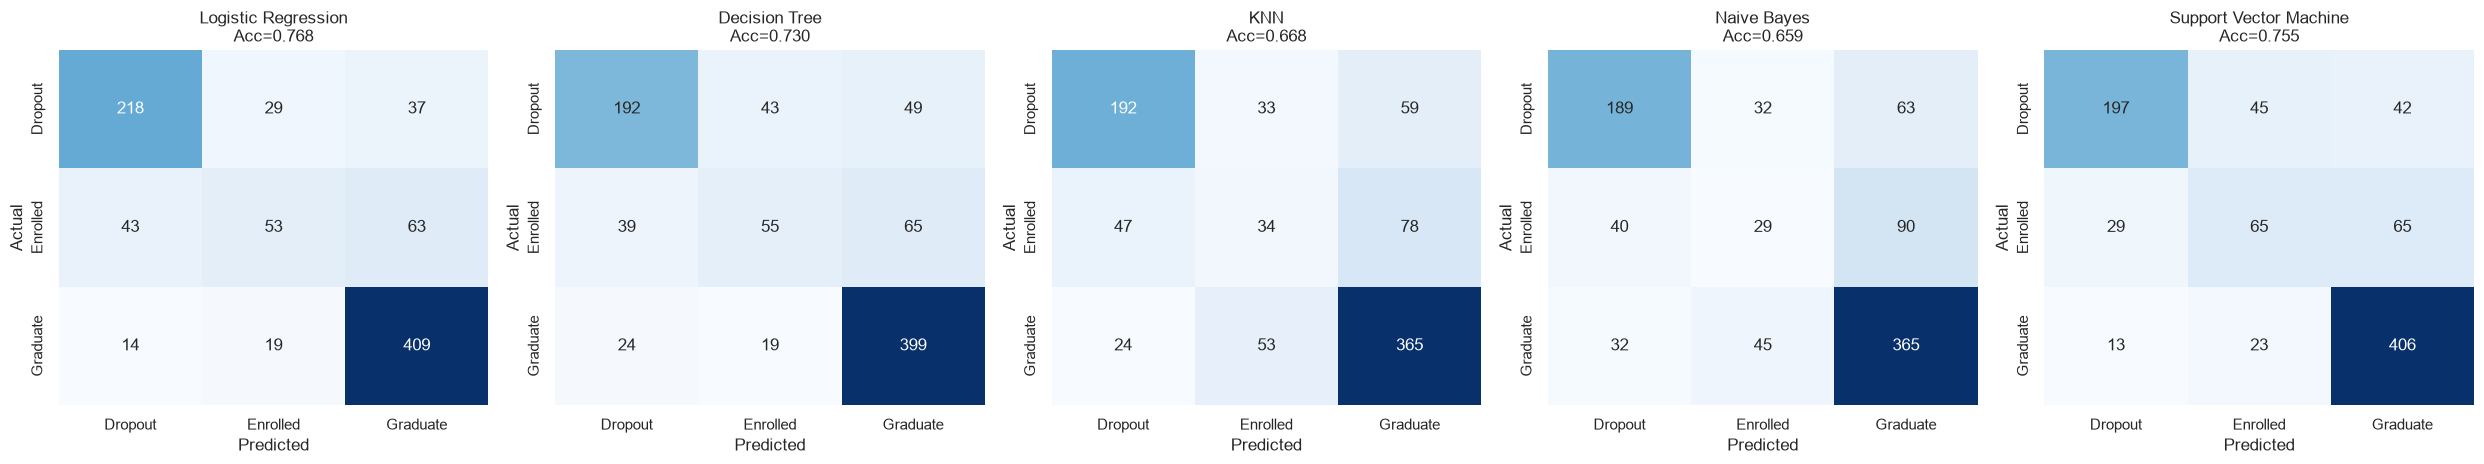

In [18]:
fig, axes = plt.subplots(1, 5, figsize=(25, 4.8))
for ax, name in zip(axes, trained_models):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set_title(f"{name}\nAcc={results[name]['Accuracy']:.3f}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

## 9. ROC curves (one-vs-rest, per class)

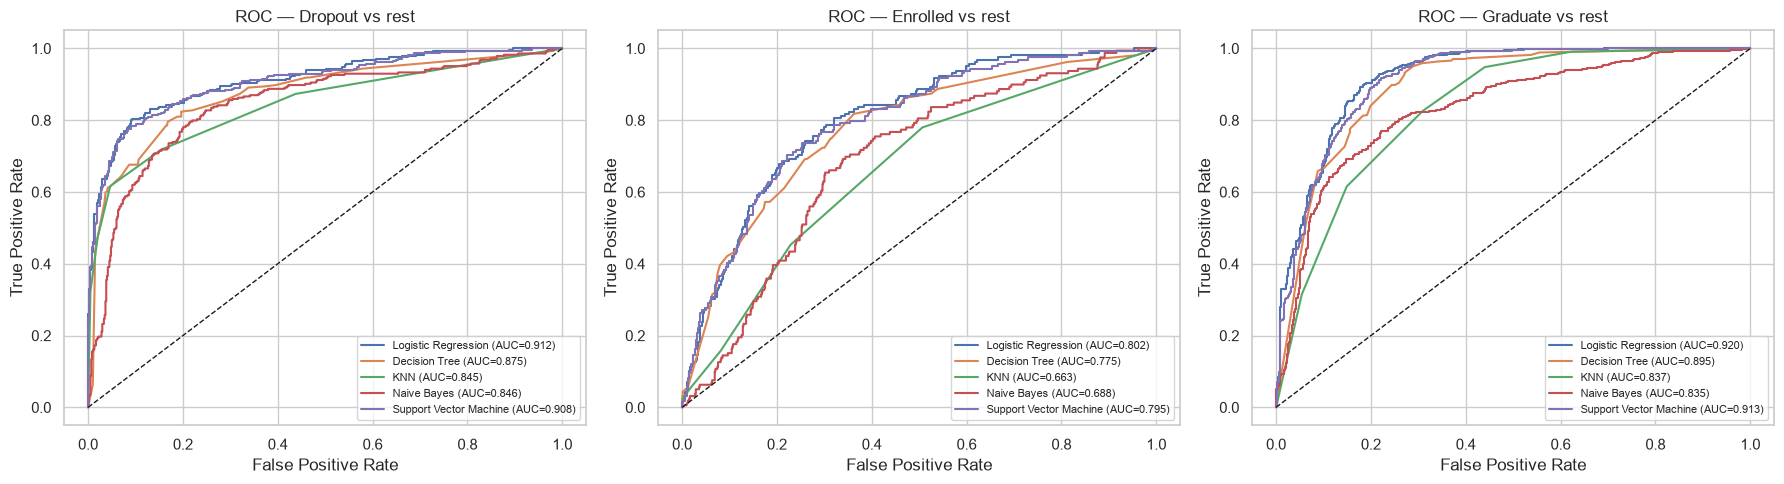

In [19]:
y_test_bin = label_binarize(y_test, classes=range(len(CLASS_NAMES)))
fig, axes = plt.subplots(1, len(CLASS_NAMES), figsize=(6 * len(CLASS_NAMES), 5))
for k, cls in enumerate(CLASS_NAMES):
    ax = axes[k]
    for name in trained_models:
        fpr, tpr, _ = roc_curve(y_test_bin[:, k], probas[name][:, k])
        ax.plot(fpr, tpr, label=f"{name} (AUC={auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_title(f"ROC — {cls} vs rest")
    ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

## 10. Model comparison chart

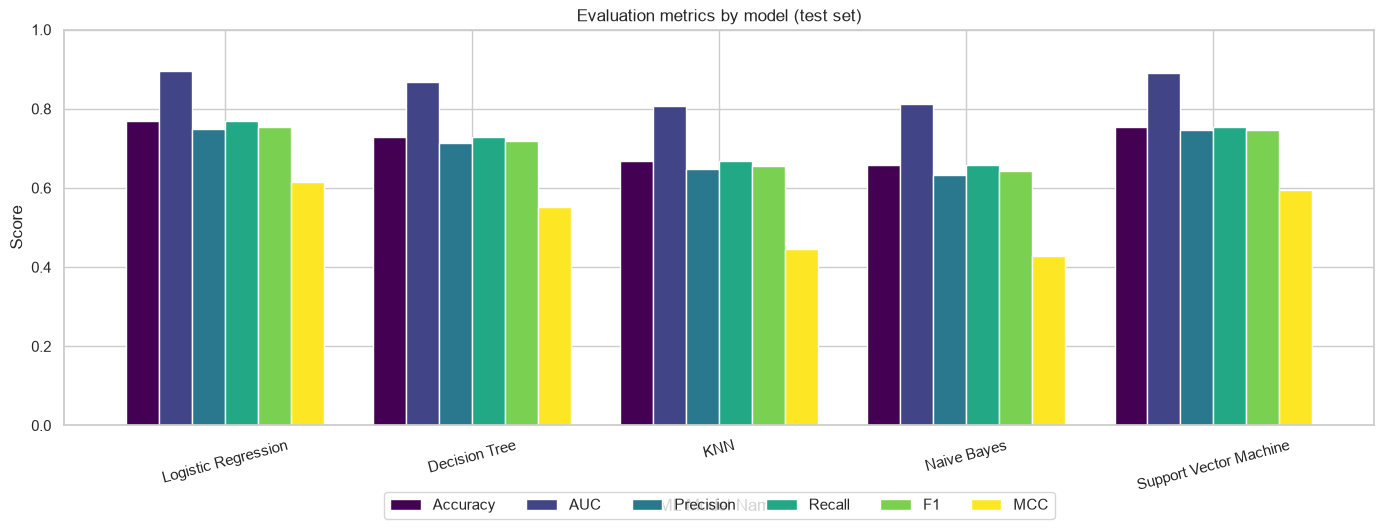

In [20]:
ax = metrics_df.plot(kind="bar", figsize=(14, 5.5), width=0.8, colormap="viridis")
ax.set_title("Evaluation metrics by model (test set)")
ax.set_ylabel("Score"); ax.set_ylim(0, 1)
ax.set_xticklabels(metrics_df.index, rotation=15)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=6)
plt.tight_layout(); plt.show()

In [21]:
# Train vs test accuracy -> quick over/under-fitting check
fit_check = pd.DataFrame({
    "Train Accuracy": {n: accuracy_score(y_train, m.predict(X_train)) for n, m in trained_models.items()},
    "Test Accuracy" : {n: results[n]["Accuracy"] for n in trained_models},
    "CV macro-F1"   : cv_scores,
})
fit_check["Train-Test Gap"] = fit_check["Train Accuracy"] - fit_check["Test Accuracy"]
fit_check.round(4)

,Train Accuracy,Test Accuracy,CV macro-F1,Train-Test Gap
Logistic Regression,0.7731,0.7684,0.6763,0.0047
Decision Tree,0.7881,0.7299,0.6698,0.0581
KNN,0.7974,0.6678,0.6102,0.1296
Naive Bayes,0.6753,0.6588,0.5751,0.0166
Support Vector Machine,0.7723,0.7548,0.6867,0.0174


## 11. Feature importance (Decision Tree & Logistic Regression)

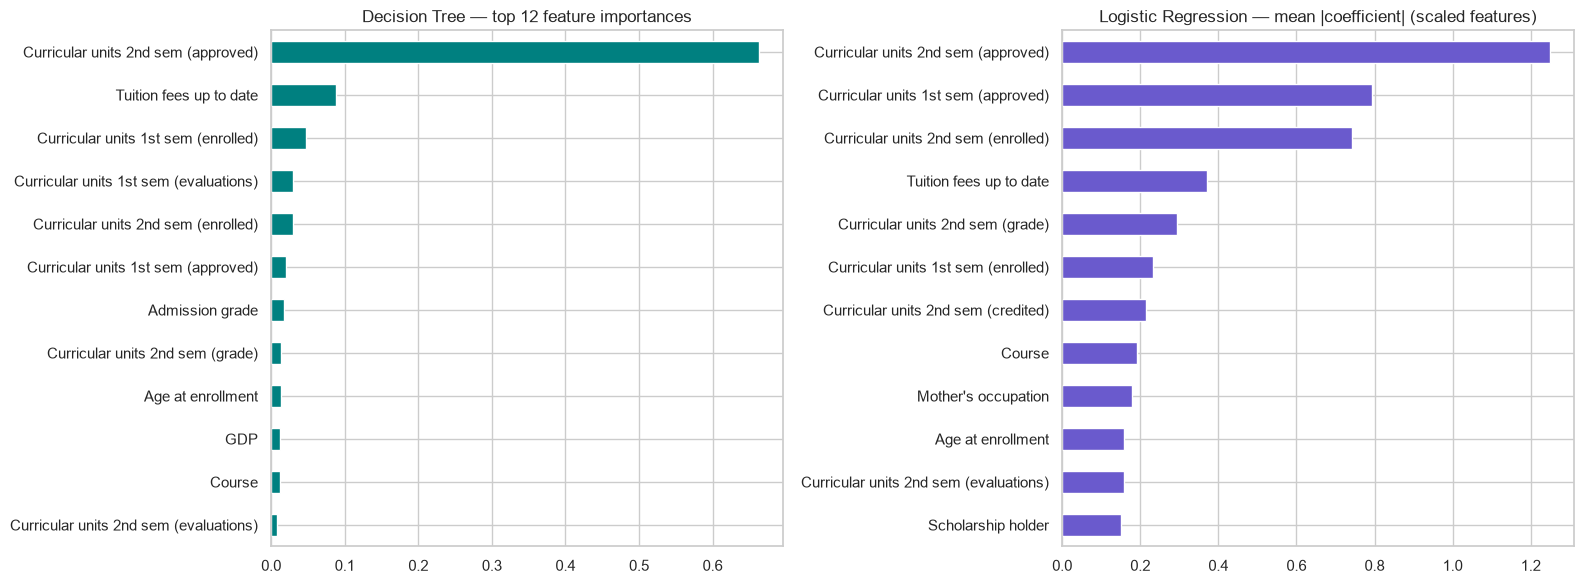

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

dt = trained_models["Decision Tree"].named_steps["clf"]
imp = pd.Series(dt.feature_importances_, index=X.columns).nlargest(12).sort_values()
imp.plot(kind="barh", ax=ax[0], color="teal")
ax[0].set_title("Decision Tree — top 12 feature importances")

lr = trained_models["Logistic Regression"].named_steps["clf"]
coef = pd.Series(np.abs(lr.coef_).mean(axis=0), index=X.columns).nlargest(12).sort_values()
coef.plot(kind="barh", ax=ax[1], color="slateblue")
ax[1].set_title("Logistic Regression — mean |coefficient| (scaled features)")
plt.tight_layout(); plt.show()

## 12. Save trained models

In [23]:
file_map = {
    "Logistic Regression"   : "logistic_regression.joblib",
    "Decision Tree"         : "decision_tree.joblib",
    "KNN"                   : "knn.joblib",
    "Naive Bayes"           : "naive_bayes.joblib",
    "Support Vector Machine": "svm.joblib",
}
for name, fname in file_map.items():
    joblib.dump(trained_models[name], os.path.join(MODEL_DIR, fname), compress=3)

with open(os.path.join(MODEL_DIR, "best_params.json"), "w") as f:
    json.dump({k: {p: (v if v is None or isinstance(v, (int, float, str)) else str(v))
                   for p, v in d.items()} for k, d in best_params.items()}, f, indent=2)

for f in sorted(os.listdir(MODEL_DIR)):
    print(f"{f:<28} {os.path.getsize(os.path.join(MODEL_DIR, f))/1024:8.1f} KB")

best_params.json                  0.3 KB
decision_tree.joblib              5.7 KB
feature_columns.json              1.0 KB
knn.joblib                      174.5 KB
label_encoder.joblib              0.5 KB
logistic_regression.joblib        3.0 KB
metrics_comparison.csv            0.3 KB
naive_bayes.joblib                3.7 KB
svm.joblib                       85.6 KB


## 13. Sanity check — reload saved models and score `test_data.csv`

In [24]:
le_loaded = joblib.load(os.path.join(MODEL_DIR, "label_encoder.joblib"))
features  = json.load(open(os.path.join(MODEL_DIR, "feature_columns.json")))
test_loaded = pd.read_csv(TEST_CSV)
test_loaded.columns = test_loaded.columns.str.strip()

X_chk = test_loaded[features]
y_chk = le_loaded.transform(test_loaded[TARGET])

reload_rows = {}
for name, fname in file_map.items():
    m = joblib.load(os.path.join(MODEL_DIR, fname))
    reload_rows[name] = evaluate(m, X_chk, y_chk)[0]

reload_df = pd.DataFrame(reload_rows).T.round(4)
print("Reloaded metrics identical to in-memory metrics:",
      np.allclose(reload_df.values, metrics_df.values))
reload_df

Reloaded metrics identical to in-memory metrics: True


,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.7684,0.8961,0.7500,0.7684,0.7531,0.6150
Decision Tree,0.7299,0.8669,0.7145,0.7299,0.7176,0.5506
KNN,0.6678,0.8082,0.6483,0.6678,0.6553,0.4465
Naive Bayes,0.6588,0.8118,0.6334,0.6588,0.6417,0.4279
Support Vector Machine,0.7548,0.8901,0.7476,0.7548,0.7464,0.5946


## 14. Summary & winner

In [25]:
ranking = metrics_df.copy()
ranking["Mean Rank"] = metrics_df.rank(ascending=False).mean(axis=1)
ranking = ranking.sort_values("Mean Rank")
display(ranking)

winner = ranking.index[0]
print(f"\nOverall winner (best average rank across 6 metrics): {winner}")
print(f"Best by MCC : {metrics_df['MCC'].idxmax()}  ({metrics_df['MCC'].max():.4f})")
print(f"Best by AUC : {metrics_df['AUC'].idxmax()}  ({metrics_df['AUC'].max():.4f})")
print(f"Best by F1  : {metrics_df['F1'].idxmax()}  ({metrics_df['F1'].max():.4f})")

,Accuracy,AUC,Precision,Recall,F1,MCC,Mean Rank
ML Model Name,,,,,,,
Logistic Regression,0.7684,0.8961,0.7500,0.7684,0.7531,0.6150,1.000000
Support Vector Machine,0.7548,0.8901,0.7476,0.7548,0.7464,0.5946,2.000000
Decision Tree,0.7299,0.8669,0.7145,0.7299,0.7176,0.5506,3.000000
KNN,0.6678,0.8082,0.6483,0.6678,0.6553,0.4465,4.166667
Naive Bayes,0.6588,0.8118,0.6334,0.6588,0.6417,0.4279,4.833333



Overall winner (best average rank across 6 metrics): Logistic Regression
Best by MCC : Logistic Regression  (0.6150)
Best by AUC : Logistic Regression  (0.8961)
Best by F1  : Logistic Regression  (0.7531)


## 15. Observations

| ML Model Name | Observation about model performance |
|---|---|
| **Logistic Regression** | Logistic Regression gave the **best overall performance**. It achieved the highest Accuracy (76.84%), AUC (89.61%), F1 Score (75.31%), and MCC (61.50%). The difference between its training and testing accuracy was also very small, suggesting that the model generalizes well. However, it had lower performance for the **Enrolled** class compared with the other two classes. |
| **Decision Tree** | The Decision Tree performed reasonably well, with an Accuracy of **72.99%** and AUC of **86.69%**. It performed better than KNN and Naive Bayes but was below Logistic Regression and SVM. The difference between training and testing accuracy also suggests some overfitting. |
| **K-Nearest Neighbors (KNN)** | KNN achieved an Accuracy of **66.78%** and AUC of **80.82%**, which was lower than the other models. Although scaling the features helps KNN, the dataset contains many integer-coded categorical variables, which can make distance-based classification less effective. |
| **Naive Bayes** | Gaussian Naive Bayes had the lowest overall performance, with an Accuracy of **65.88%**, AUC of **81.18%**, and MCC of **42.79%**. Its performance was lower than the other models, which may be related to the assumptions made by the Gaussian Naive Bayes model about the features. |
| **Support Vector Machine (SVM)** | SVM was the **second-best performing model** after Logistic Regression. It achieved an Accuracy of **75.48%**, AUC of **89.01%**, and F1 Score of **74.64%**. Its results were close to Logistic Regression, showing that it was also effective on this dataset. |
| **Overall Winner** | **Logistic Regression was the best-performing model in this experiment.** It achieved the highest values across the main evaluation metrics, while SVM was a close second. KNN and Naive Bayes performed the weakest overall. The **Enrolled** class was the most difficult class to predict for the models. |